# Euro-USD Exchange Rate: Impact of Presidencies and Economics

*Goal:* 
1) Identify the change in the Euro-USD exchange rate during the 2008 financial crisis
2) Identify the change in the Euro-USD exchange rate under the various US presidencies

*Dataset Introduction:* 

The dataset collects its information from the European Central Bank and can be accessed through [this link](https://www.kaggle.com/datasets/lsind18/euro-exchange-daily-rates-19992020). The dataset details the euro daily exchange rates from 2000 to 2021. The euro is the offical currency in most countries of the European Union. An exchange rate is the value of one currency compared to the value of another. For example, the exchange rate of 1 USD is 158.19 Japanese Yen. So if something in Japan costs 158.19 Yen, it is like buying something for 1 USD. 

*Analysis Findings:*
* The Euro-USD exchange rate was the highest between the years 2000-2021 when it was valued at 1.599 in 2008.
* The greatest fluctuations in the exchange rate occur during George W. Bush's presidency (2001-2009).

For more details, see the full analysis below.

## Dataset Initiation and Exploration

*Initiation:* We will begin our project by reading in the data and any necessary modules for our analysis later. 

In [1]:
#import modules for data analysis and graph creation
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

*Exploration:* We will sift through the dataset to gain pertinent information for our analysis and determine what areas of the data need cleaning. 

In [2]:
#read in the dataset file
exchange_rates = pd.read_csv('euro_daily_hist_1999_2020.csv')

exchange_rates.head()

,Period\Unit:,[Australian dollar ],[Bulgarian lev ],[Brazilian real ],[Canadian dollar ],[Swiss franc ],[Chinese yuan renminbi ],[Cypriot pound ],[Czech koruna ],[Danish krone ],...,[Romanian leu ],[Russian rouble ],[Swedish krona ],[Singapore dollar ],[Slovenian tolar ],[Slovak koruna ],[Thai baht ],[Turkish lira ],[US dollar ],[South African rand ]
0,2021-01-08,1.5758,1.9558,6.5748,1.5543,1.0827,7.9184,NaN,26.163,7.4369,...,4.8708,90.8000,10.0510,1.6228,NaN,NaN,36.8480,9.0146,1.2250,18.7212
1,2021-01-07,1.5836,1.9558,6.5172,1.5601,1.0833,7.9392,NaN,26.147,7.4392,...,4.8712,91.2000,10.0575,1.6253,NaN,NaN,36.8590,8.9987,1.2276,18.7919
2,2021-01-06,1.5824,1.9558,6.5119,1.5640,1.0821,7.9653,NaN,26.145,7.4393,...,4.8720,90.8175,10.0653,1.6246,NaN,NaN,36.9210,9.0554,1.2338,18.5123
3,2021-01-05,1.5927,1.9558,6.5517,1.5651,1.0803,7.9315,NaN,26.227,7.4387,...,4.8721,91.6715,10.0570,1.6180,NaN,NaN,36.7760,9.0694,1.2271,18.4194
4,2021-01-04,1.5928,1.9558,6.3241,1.5621,1.0811,7.9484,NaN,26.141,7.4379,...,4.8713,90.3420,10.0895,1.6198,NaN,NaN,36.7280,9.0579,1.2296,17.9214


From first glance, rows are seperated by date and columns are seperated by country. There are a few countries with 'NaN' values. 

In [3]:
#information about dataset
exchange_rates.info()

<class 'pandas.DataFrame'>
RangeIndex: 5699 entries, 0 to 5698
Data columns (total 41 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Period\Unit:              5699 non-null   str    
 1   [Australian dollar ]      5699 non-null   str    
 2   [Bulgarian lev ]          5297 non-null   str    
 3   [Brazilian real ]         5431 non-null   str    
 4   [Canadian dollar ]        5699 non-null   str    
 5   [Swiss franc ]            5699 non-null   str    
 6   [Chinese yuan renminbi ]  5431 non-null   str    
 7   [Cypriot pound ]          2346 non-null   str    
 8   [Czech koruna ]           5699 non-null   str    
 9   [Danish krone ]           5699 non-null   str    
 10  [Estonian kroon ]         3130 non-null   str    
 11  [UK pound sterling ]      5699 non-null   str    
 12  [Greek drachma ]          520 non-null    str    
 13  [Hong Kong dollar ]       5699 non-null   str    
 14  [Croatian kuna ]   

The above output reveals 4 facts about the dataset:
1) There are 5,699 rows in the dataset and 41 columns. Of those 41 columns, 40 are unique contries.
2) All of the columns are non-numeric dtypes with the exception of the 'Turkish lira', 'Romanian leu', and the 'Iceland krona'.
3) There are 8 columns with around 2,000 or more 'NaN' values.
4) None of the column titles are in Python's preferred format style, snakecase. 

We will want to change the column titles and convert the dtypes to a numeric value. Since the focus of this project is between the exchange rate of the USA and the EU, we will only spend time converting those columns to numerical dtypes. 

## Data Cleaning

Before we being our analysis, we are going to take these steps to prepare the data:
1) Change the column titles: 'Period\Unit' to 'Time' and '[US Dollar ]' to 'us_dollar'
2) Change the 'time' column to an datetime dtype
3) Sort the 'time' column values in ascending order
4) Convert the 'us_dollar' column dtpye to a numerical value

**1.** *Change the column titles: 'Period\Unit' to 'time' and '[US Dollar ]' to 'us_dollar'*

In [4]:
#dictionary to rename column titles
column_names = {
    'Period\\Unit:': 'time',
    '[US dollar ]': 'us_dollar'
}

#rename attribute (expects dictionary)
exchange_rates.rename(columns=column_names, inplace=True)

exchange_rates.head()

,time,[Australian dollar ],[Bulgarian lev ],[Brazilian real ],[Canadian dollar ],[Swiss franc ],[Chinese yuan renminbi ],[Cypriot pound ],[Czech koruna ],[Danish krone ],...,[Romanian leu ],[Russian rouble ],[Swedish krona ],[Singapore dollar ],[Slovenian tolar ],[Slovak koruna ],[Thai baht ],[Turkish lira ],us_dollar,[South African rand ]
0,2021-01-08,1.5758,1.9558,6.5748,1.5543,1.0827,7.9184,NaN,26.163,7.4369,...,4.8708,90.8000,10.0510,1.6228,NaN,NaN,36.8480,9.0146,1.2250,18.7212
1,2021-01-07,1.5836,1.9558,6.5172,1.5601,1.0833,7.9392,NaN,26.147,7.4392,...,4.8712,91.2000,10.0575,1.6253,NaN,NaN,36.8590,8.9987,1.2276,18.7919
2,2021-01-06,1.5824,1.9558,6.5119,1.5640,1.0821,7.9653,NaN,26.145,7.4393,...,4.8720,90.8175,10.0653,1.6246,NaN,NaN,36.9210,9.0554,1.2338,18.5123
3,2021-01-05,1.5927,1.9558,6.5517,1.5651,1.0803,7.9315,NaN,26.227,7.4387,...,4.8721,91.6715,10.0570,1.6180,NaN,NaN,36.7760,9.0694,1.2271,18.4194
4,2021-01-04,1.5928,1.9558,6.3241,1.5621,1.0811,7.9484,NaN,26.141,7.4379,...,4.8713,90.3420,10.0895,1.6198,NaN,NaN,36.7280,9.0579,1.2296,17.9214


**2.** *Change the 'time' column to an datetime dtype*

In [5]:
#pass Series through 'to_datetime' attribute for datetime dtype
exchange_rates['time'] = pd.to_datetime(exchange_rates['time'])

exchange_rates['time'].dtypes

dtype('<M8[us]')

**3.** *Sort the 'time' column values in ascending order*

In [6]:
#sort in ascending order
exchange_rates.sort_values('time', inplace=True)

#reset index so farthest 'Time' has index of 0
exchange_rates.reset_index(drop=True, inplace=True)

**4.** *Convert 'us_dollar' column dtpye to a numerical value*

In [7]:
#review values in 'us_dollar' column
exchange_rates['us_dollar'].value_counts()

us_dollar
-         62
1.2276     9
1.1215     8
1.1305     7
1.0867     6
          ..
1.2109     1
1.2162     1
1.2140     1
1.2189     1
1.2193     1
Name: count, Length: 3528, dtype: int64

It appears as though we have a few rows where there is a '-' symbol instead of a number value. Before we convert this column to contain numerical dtypes, we need to remove that symbol.

In [8]:
#keep all rows where the value is not this symbol '-'
clean_exchange_rates = exchange_rates[exchange_rates['us_dollar'] != '-']

Now we need to verify removing the '-' character worked.

In [9]:
#review values in 'us_dollar' column
clean_exchange_rates['us_dollar'].value_counts()

us_dollar
1.2276    9
1.1215    8
1.1305    7
1.0867    6
1.1218    6
         ..
1.2109    1
1.2162    1
1.2140    1
1.2189    1
1.2193    1
Name: count, Length: 3527, dtype: int64

Our task was sucessful. Now let's convert the column to a float dtype.

In [10]:
#convert to float dtype
clean_exchange_rates['us_dollar'] = clean_exchange_rates['us_dollar'].astype(float)

clean_exchange_rates['us_dollar'].dtype

dtype('float64')

That concludes the last step necessary for preparing our data for analysis.

## Rolling Mean

We want to determine the change of the exchange rate between the USD and the euro over time. To do this we will first isolate the 'time' column and 'us_dollar' column to its own variable and then plot the relationship on a time graph. 

In [11]:
#isolate 'time' and 'us_dollar'
euro_to_dollar = clean_exchange_rates[['time', 'us_dollar']].copy()

#reset index so farthest 'time' has index of 0 (index needed to be reset after '-' removal)
euro_to_dollar.reset_index(drop=True, inplace=True)

euro_to_dollar.head()

,time,us_dollar
0,1999-01-04,1.1789
1,1999-01-05,1.1790
2,1999-01-06,1.1743
3,1999-01-07,1.1632
4,1999-01-08,1.1659


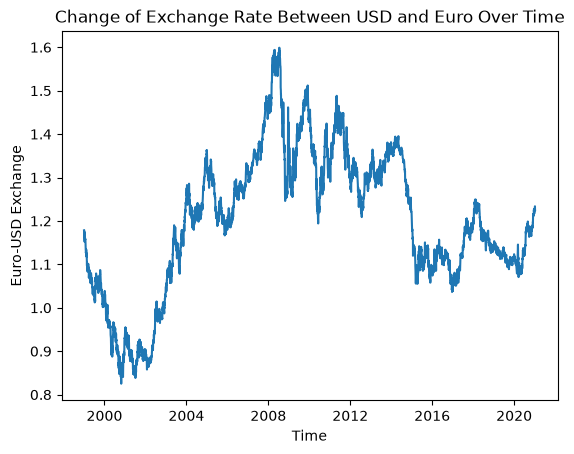

In [12]:
#plot change over time
plt.plot(euro_to_dollar['time'], euro_to_dollar['us_dollar'])
plt.xlabel('Time')
plt.ylabel('Euro-USD Exchange')
plt.title('Change of Exchange Rate Between USD and Euro Over Time')
plt.show()

Nice output here. It apears the lowest exchange rate was in late 2000 or early 2001 at around 0.8 and the maximum exchange rate was in 2008 at around 1.6. 

Next, let's use a rolling mean to output a smoother looking graph that still represents the changes over time. 

In [13]:
#calculate rolling mean and set to new column
euro_to_dollar['rolling_mean'] = euro_to_dollar['us_dollar'].rolling(30).mean()

euro_to_dollar

,time,us_dollar,rolling_mean
0,1999-01-04,1.1789,NaN
1,1999-01-05,1.1790,NaN
2,1999-01-06,1.1743,NaN
3,1999-01-07,1.1632,NaN
4,1999-01-08,1.1659,NaN
...,...,...,...
5632,2021-01-04,1.2296,1.211170
5633,2021-01-05,1.2271,1.212530
5634,2021-01-06,1.2338,1.213987
5635,2021-01-07,1.2276,1.215357


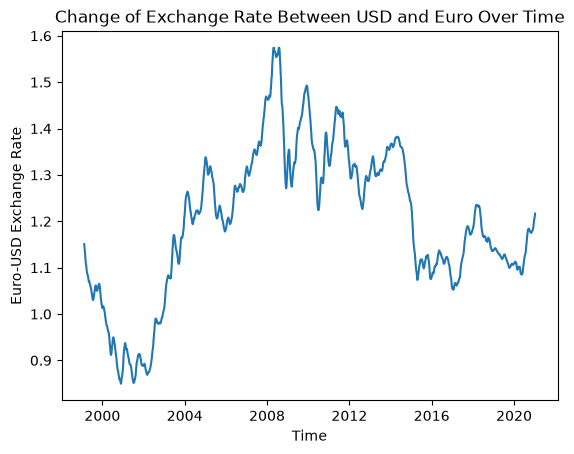

In [14]:
#plot change over time with rolling mean
plt.plot(euro_to_dollar['time'], euro_to_dollar['rolling_mean'])
plt.xlabel('Time')
plt.ylabel('Euro-USD Exchange Rate')
plt.title('Change of Exchange Rate Between USD and Euro Over Time')
plt.show()

The integrity of the graph is still intact without all of the distracting squiggles. 

## 2008 Financial Crisis

Our next task for this project is to create a graph that clearly depicts what the Euro-USD exchange rate was doing during the 2008 financial crisis in the USA. 

In order to maximize the graph's data-ink ratio, we will remove all ticks, label, and spines except for the most relevant ones. Our graph will only plot data from mid 2005 to the beginning of 2010 and will highlight the line during the financial crisis.  

Before jumping into the code for the graph, we need to find a handful of index numbers. Since our graph focuses on 2005-2010 we need to find where those data points are located in the dataset. We will use `DataFrame.iloc` to find the indices for the needed dates. We will do this for a handful of additional dates and place them before the graph code. After the graph is output, we will explain the reason we chose those specific dates for plotting. 

In [15]:
#index of mid 2005
euro_to_dollar.iloc[1651:1654, :]

,time,us_dollar,rolling_mean
1651,2005-06-14,1.2110,1.252830
1652,2005-06-15,1.2069,1.249883
1653,2005-06-16,1.2115,1.247087


The index for mid 2005 (2005-06-15 in our case) is 1652. We also output one value before the target index and one value after. The next four cells of code follow this format.

In [ ]:
#index where 2009 rolls over to 2010
euro_to_dollar.iloc[2815:2818, :]

In [ ]:
#december 2007
euro_to_dollar.iloc[2284:2287, :]

In [ ]:
#september 2008
euro_to_dollar.iloc[2473:2497, :]

In [ ]:
#june 2009
euro_to_dollar.iloc[2662:2665, :]

In [ ]:
#max value in the dataset
euro_to_dollar['us_dollar'].max()

Below is the code responsible for the graph output.

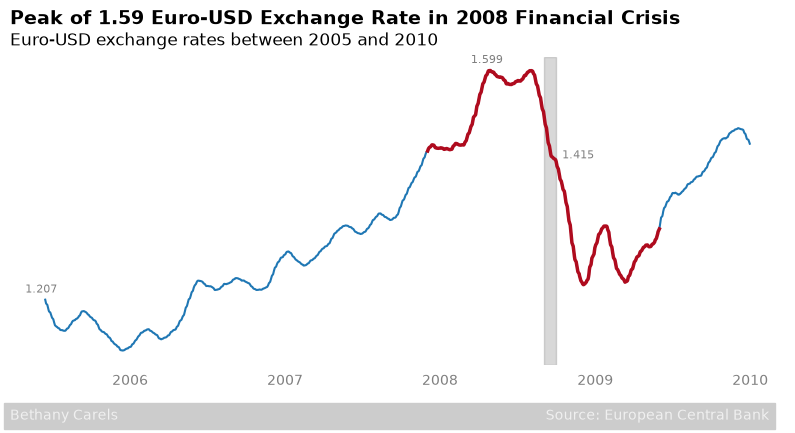

In [21]:
#figure size and plot time dimensions (2005-2010)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(euro_to_dollar['time'][1652:2816], 
        euro_to_dollar['rolling_mean'][1652:2816])

#remove the horizontal and vertical lines
for location in ['left', 'right', 'bottom', 'top']:
    ax.spines[location].set_visible(False)

#remove tick marks, y_labels, and make x_labels grey
ax.tick_params(bottom=False, left=False)
ax.set_yticklabels([])
ax.tick_params(axis='x', colors='grey')

#highlight december 2007 to june 2009
ax.plot(euro_to_dollar['time'][2285:2664], 
        euro_to_dollar['rolling_mean'][2285:2664],
        color='#af0b1e', 
        linewidth=2.5)

#highlight the peak of financial crash in sept of 2008
june_begin = pd.to_datetime('2008-09-01')
june_end = pd.to_datetime('2008-09-30')

ax.axvspan(xmin=june_begin, xmax=june_end,
           alpha=0.3, color='grey')

#add exchange rate values 
ax.text(12902, 1.26, '1.207', size=8, alpha=0.5)
ax.text(13952, 1.585, '1.599', size=8, alpha=0.5)
ax.text(14167, 1.45, '1.415', size=8, alpha=0.5)

#add title and subtitle
ax.text(12866.0, y=1.64, s='Peak of 1.59 Euro-USD Exchange Rate in 2008 Financial Crisis', size=14, weight='bold')
ax.text(12866.0, y=1.61, s='Euro-USD exchange rates between 2005 and 2010', size=12)

#add signature
ax.text(12866.0, 1.08, (f'Bethany Carels {' '*105} Source: European Central Bank'),
        color = '#f0f0f0', backgroundcolor = '0.8',
        size=10)

plt.show()

In [22]:
#find the limits of x and y on the graph
x_limits = ax.get_xlim()
y_limits = ax.get_ylim()

print(x_limits, y_limits)

(np.float64(12866.0), np.float64(14692.0)) (np.float64(1.1580608333333333), np.float64(1.5941558333333332))


Our graph shows that during the 2008 financial crisis, the Euro-USD exchange rate hit the highest ever recorded in the dataset. According to the Federal Housing Finance Agency House Price Index, house prices peaked at the beginning of 2007. Later, the National Bureau of Economic Research identified December of 2007 as being the beginning of the recession. The recession peaked in September of 2008 and was finally considered over in June of 2009. For more information about the recession, visit the [Federal Reserve History](https://www.federalreservehistory.org/essays/great-recession-and-its-aftermath) site.

The graph is highlighted red from December 2007 to June 2009 to reflect the offical dates of the recession. The peak of the recession in September of 2008 is marked by the gray strip. As we can see from the graph the Euro-USD exchange rate hit 1.599 in 2008 before it began to fluctuate downwards.  

## Exchange-Rate by President 

The final graph we will create depicts the change of the Euro-USD exchange rate across the three presidencies of 2001 to 2021. We follow a similar indexing approach for identifying important dates in the dataset. Below is the code to our graph. 

In [ ]:
#jan 20, 2009
euro_to_dollar.iloc[2571:2574, :]

In [ ]:
#jan 20 2017
euro_to_dollar.iloc[4623:4626, :]

In [ ]:
#jan 20, 2001
euro_to_dollar.iloc[527:530, :]

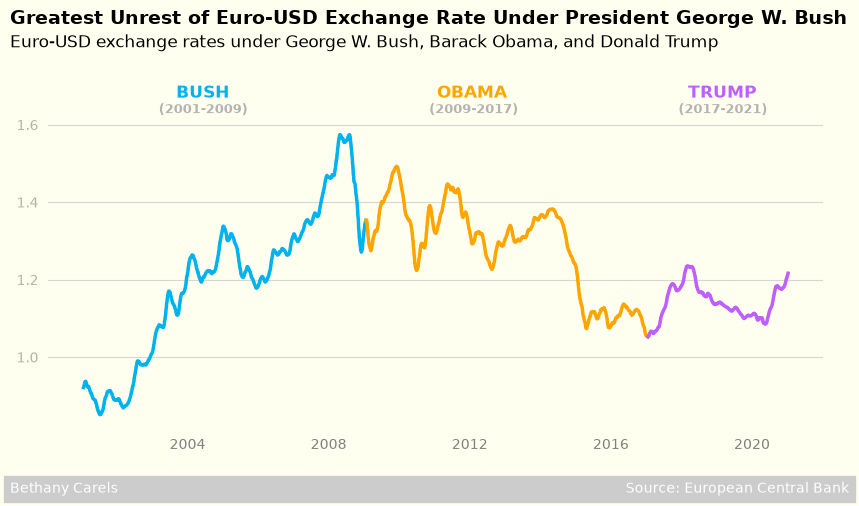

In [26]:
#figure size, plot time dimensions, and outside graph color
fig, ax = plt.subplots(figsize=(10, 4), facecolor='ivory')
ax.plot(euro_to_dollar['time'][527:], 
        euro_to_dollar['rolling_mean'][527:])

#remove the horizontal and vertical lines
for location in ['left', 'right', 'bottom', 'top']:
    ax.spines[location].set_visible(False)

#remove tick marks, y_labels, and make x_labels grey
ax.tick_params(bottom=False, left=False)
ax.set_yticklabels([])
ax.tick_params(axis='x', colors='grey')

#highlight beginning of graph to 1-20-2009 (george w. bush)
ax.plot(euro_to_dollar['time'][527:2573], 
        euro_to_dollar['rolling_mean'][527:2573],
        color='#00B2EE', 
        linewidth=2.5)
#add name and presidency date
ax.text(12300, 1.67, 'BUSH', color='#00B2EE', size=12, weight='bold')
ax.text(12120, 1.63, '(2001-2009)', color='0.7', size=9, weight='bold')


#highlight 1-20-2009 to 1-20-2017 (barack obama)
ax.plot(euro_to_dollar['time'][2572:4625], 
        euro_to_dollar['rolling_mean'][2572:4625],
        color='#ffa500', 
        linewidth=2.5)
#add name and presidency date
ax.text(15000, 1.67, 'OBAMA', color='#ffa500', size=12, weight='bold')
ax.text(14920, 1.63, '(2009-2017)', color='0.7', size=9, weight='bold')


#highlight 1-20-2017 to 1-20-2021 (donald trump)
ax.plot(euro_to_dollar['time'][4624:], 
        euro_to_dollar['rolling_mean'][4624:],
        color='#BF5FFF', 
        linewidth=2.5)
#add name and presidency date
ax.text(17600, 1.67, 'TRUMP', color='#BF5FFF', size=12, weight='bold')
ax.text(17500, 1.63, '(2017-2021)', color='0.7', size=9, weight='bold')

#add y-axis line and coordinates
ax.set_yticks([1.0, 1.2, 1.4, 1.6])
ax.set_yticklabels(['1.0', '1.2','1.4', '1.6'], alpha=0.3)
ax.grid(axis='y', alpha=0.5)

#add title and subtitle
ax.text(10580, y=1.86, s='Greatest Unrest of Euro-USD Exchange Rate Under President George W. Bush', size=14, weight='bold')
ax.text(10580, y=1.8, s='Euro-USD exchange rates under George W. Bush, Barack Obama, and Donald Trump', size=12)

#add signature
ax.text(10580, 0.65, (f'Bethany Carels {' '*125} Source: European Central Bank'),
        color = 'white', backgroundcolor = '0.8',
        size=10)

#set graph color 
ax.set_facecolor("ivory")

plt.show()

From the graph above we can see how the Euro-USD exchange rate changes from 2001-2021 under different presidencies. 

During George W. Bush's presidency we see the greatest fluctuations in the exchange rate. If we remember from our previous graph, the 2008 financial crisis occured during Bush's presidency and resolved near the beginning of Barack Obama's presidency. We continue to see fluctuations in the Euro-USD exchange rate under Obama and Donald Trump, but to lesser degrees than what is seen under Bush. 

## Conclusion

From our analysis we saw that: 
* The Euro-USD exchange rate was the highest between the years 2000-2021 when it was valued at 1.599 in 2008.
* The greatest fluctuations in the exchange rate occur during George W. Bush's presidency (2001-2009).